# Session 10 – Python code from the session notes

This notebook contains the code shown in the Session 10 notes, with the output it produced. It uses the same packages and functions as Tutorial 10 and the same data file, `energy_load.csv`: 40 one-hour server benchmark runs in random order, with processor load (%) as the predictor and energy use (kWh) as the response. The column `day` is the run number, i.e. the order in which the runs were carried out.

Step numbers refer to the eight steps of a regression analysis in the Session 10 notes (Brooks, Section 10.7).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import probplot

candidates = [Path("../../data"), Path("../data"), Path("data")]
DATA = next(p for p in candidates if p.exists())
df = pd.read_csv(DATA / "energy_load.csv")
x = df["cpu_load_pct"]      # predictor (%)
y = df["energy_kwh"]        # response (kWh)
print(len(df), "runs; load from", x.min(), "to", x.max(), "%")

40 runs; load from 17.3 to 92.71 %


## 1. Scatterplot (Steps 3–4)

Look before fitting: direction, curvature, changing spread, unusual points, gaps in the load range.

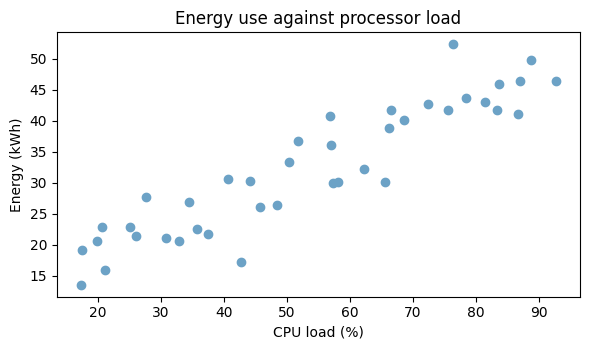

In [2]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(x, y, color="#6CA2C6")
ax.set_xlabel("CPU load (%)")
ax.set_ylabel("Energy (kWh)")
ax.set_title("Energy use against processor load")
plt.tight_layout()
plt.show()

## 2. Fit the line: coefficients (Step 4)

The model is fitted once here and reused in the later sections. Results in the notes: $\hat\beta_0 = 10.134$ kWh (`const`) and $\hat\beta_1 = 0.4161$ kWh per percentage point (`cpu_load_pct`).

In [3]:
X = sm.add_constant(x)            # adds the intercept column
model = sm.OLS(y, X).fit()        # least squares, fitted once
print(model.params)

const           10.134021
cpu_load_pct     0.416137
dtype: float64


In plain language: one percentage point more load goes with about 0.42 kWh more energy on average. The intercept (10.1 kWh at 0% load) lies outside the observed range of 17–93% and is not the idle energy.

## 3. Residual diagnostics and influence (Step 5)

Residual versus fitted: linearity and constant spread. Residual versus run order: drift or dependence. QQ-plot: normal errors. Cook's distance: does one run change the line?

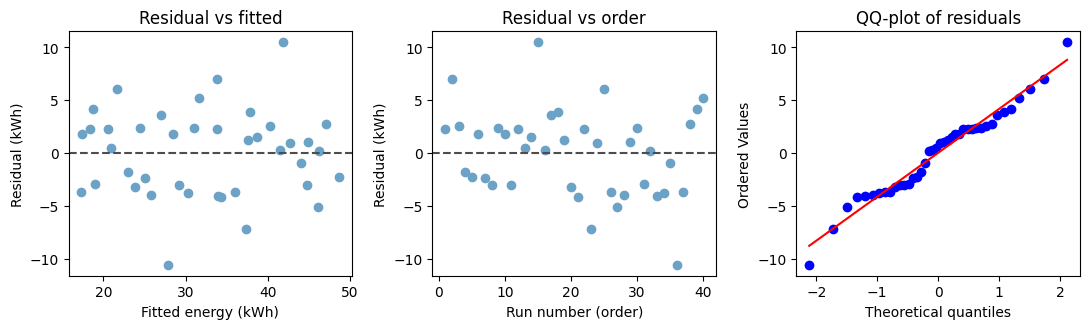

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].scatter(model.fittedvalues, model.resid, color="#6CA2C6")
axes[0].axhline(0, color="0.3", linestyle="--")
axes[0].set(xlabel="Fitted energy (kWh)", ylabel="Residual (kWh)", title="Residual vs fitted")
axes[1].scatter(df["day"], model.resid, color="#6CA2C6")
axes[1].axhline(0, color="0.3", linestyle="--")
axes[1].set(xlabel="Run number (order)", ylabel="Residual (kWh)", title="Residual vs order")
probplot(model.resid, dist="norm", plot=axes[2])
axes[2].set_title("QQ-plot of residuals")
plt.tight_layout()
plt.show()

In [5]:
cooks = model.get_influence().cooks_distance[0]
i = np.argmax(cooks)
print(f"largest Cook's distance: run {df.loc[i, 'day']}, D = {cooks[i]:.3f}")

largest Cook's distance: run 15, D = 0.177


In [6]:
# refit without that run: does the slope change much?
keep = df.index != i
model_wo = sm.OLS(y[keep], X[keep]).fit()
print(f"slope with all runs: {model.params['cpu_load_pct']:.3f}, without run {df.loc[i, 'day']}: {model_wo.params['cpu_load_pct']:.3f}")

slope with all runs: 0.416, without run 15: 0.404


In plain language: the residual plots show no clear curvature, funnel or drift, and no single run dominates the fit: leaving out run 15, the run with the largest Cook's distance (about 0.18), changes the slope only from 0.416 to 0.404 kWh per percentage point. Two runs have residuals of about ±10 kWh; they are checked in the run log, not deleted.

## 4. Slope test: the model summary (Step 6)

The same fitted `model` as in section 2; nothing is refitted. Results in the notes: $\operatorname{SE}(\hat\beta_1) = 0.0287$, $t = 14.48$ with 38 df, 95% CI $[0.358;\ 0.474]$, $R^2 = 0.847$, $F = t^2 = 209.6$. Read the `cpu_load_pct` row: `coef`, `std err`, `t`, `P>|t|` and `[0.025  0.975]`.

In [7]:
print(model.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:             energy_kwh   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.842
No. Observations:                  40   F-statistic:                     209.6
Covariance Type:            nonrobust   Prob (F-statistic):           4.77e-17
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           10.1340      1.668      6.074      0.000       6.757      13.511
cpu_load_pct     0.4161      0.029     14.477      0.000       0.358       0.474

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.


In plain language: within the tested range of 17–93% load, mean energy use rises by about 0.42 kWh per percentage point of load (95% CI 0.36 to 0.47 kWh); a slope of zero is clearly ruled out.

## 5. Mean response and one new run at 70% load (Step 7)

Results in the notes: $\hat y_0 = 39.26$ kWh; 95% CI for the mean $[37.62;\ 40.91]$; 95% prediction interval for one new run $[30.71;\ 47.82]$. `mean_ci_*` is the mean response, `obs_ci_*` is one new observation.

In [8]:
new = pd.DataFrame({"const": [1.0], "cpu_load_pct": [70.0]})
frame = model.get_prediction(new).summary_frame(alpha=0.05)
print(frame.round(2))

    mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  39.26     0.81          37.62          40.91         30.71         47.82


In plain language: at 70% load the *mean* energy use is estimated to lie between 37.6 and 40.9 kWh, but a *single* new run at 70% can be expected anywhere between about 30.7 and 47.8 kWh. Loads outside 17–93% would be extrapolation: the data cannot check the line there, so a prediction needs an engineering reason.